# The classical mean-size equation on one blast, with Cunningham's strength correction

**Level 1: Fundamentals** · Needs: 01-the-data/02-geometry-reconstruction · Reading time: about 20 minutes

## Objectives

The oldest rung of the ladder is a closed-form equation: Kuznetsov's 1973 mean size with the explosive-strength correction that Cunningham added. It needs no training data, only a geometry in metres and one number for the rock. This notebook runs it on a single blast and then on a whole campaign.

By the end you will have:

- written the equation out term by term and matched the engine's `kuznetsov_x50_m` on the Enusa blast `En1`;
- seen the prediction of all 12 Enusa blasts against the measurements and read the committed artifact's number for the same blast;
- understood what the single rock factor `A` stands for, which the next notebook opens.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 12 Enusa blasts, with measured `x50` | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The equation as printed | Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 2 and 3) | the equation is reproduced with citation | the engine's `kuznetsov_x50_m` |
| The committed Enusa case | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/real-enusa/case.json` |

## Method

The mean fragment size in centimetres is

```
x50 = A * (V / Q)^0.8 * Q^(1/6) * (RWS / 115)^(-19/30)
```

with `V` the rock volume broken per hole (m3), `Q` the explosive mass in it (kg), `RWS` the relative weight strength of the explosive on the scale where ANFO is 100, and `A` the rock factor. The factor 115 is the strength of TNT on that scale, and the exponent -19/30 is Cunningham's correction as printed by Hudaverdi, Kulatilake and Kuzu 2010 (https://doi.org/10.1002/nag.957, Eq. 1) and by Amoako, Jha and Zhong 2022 (https://doi.org/10.3390/mining2020013, Eqs. 2 and 3). Two spellings of the exponent circulate (-19/30 and -19/20); the engine uses -19/30 as the two papers print it and keeps -19/20 as a named variant. Every blast of this corpus used ANFO, so the choice only rescales the rock factor recovered from the published predictions; the SDD records that the preference is not checked against Cunningham's own text.

Read the terms: `(V/Q)^0.8` is the reciprocal powder factor, so a richer charge gives a finer fragmentation; `Q^(1/6)` lets a larger hole fragment slightly coarser at the same powder factor; the strength term makes a stronger explosive finer.

### Step 1: the blast and its pattern

The cell loads the corpus, picks `En1` and reconstructs its absolute pattern (the previous topic's notebook 02). The rock factor of Enusa is read from the engine's table of per-site factors, `SITE_ROCK_FACTOR`; where that number comes from is the subject of the next notebook.

In [2]:
# Imports, the corpus, one blast and its reconstructed pattern
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
blast = next(b for b in train if b.blast_id == "En1")
pattern = bf.reconstruct_pattern(blast)
rock_factor = bf.SITE_ROCK_FACTOR[blast.site]
print("blast", blast.blast_id, "|", blast.site, "| rock factor A =", rock_factor)
print(f"V = {pattern.rock_volume_m3:.3f} m3 | Q = {pattern.charge_mass_kg:.3f} kg | RWS = {pattern.explosive.rws:g} ({pattern.explosive.name})")

blast En1 | Enusa | rock factor A = 10.97
V = 150.238 m3 | Q = 72.114 kg | RWS = 100 (ANFO)


### Step 2: the equation, one term per line

Each factor of the equation gets its own variable, so every intermediate is visible. The last line compares the product with the engine's `kuznetsov_x50_m`.

In [3]:
# The four factors of the equation, then their product in centimetres and metres
V = pattern.rock_volume_m3
Q = pattern.charge_mass_kg
volume_term = (V / Q) ** 0.8
hole_term = Q ** (1 / 6)
strength_term = (pattern.explosive.rws / 115.0) ** (-19.0 / 30.0)
x50_cm = rock_factor * volume_term * hole_term * strength_term
print(f"(V/Q)^0.8 = {volume_term:.4f}   Q^(1/6) = {hole_term:.4f}   (RWS/115)^(-19/30) = {strength_term:.4f}")
print(f"x50 = {x50_cm:.2f} cm = {x50_cm / 100:.4f} m   (by hand)")
engine = bf.kuznetsov_x50_m(pattern, rock_factor)
print(f"x50 = {engine:.4f} m   (engine)   equal: {abs(engine - x50_cm / 100) < 1e-12}")

(V/Q)^0.8 = 1.7989   Q^(1/6) = 2.0402   (RWS/115)^(-19/30) = 1.0926
x50 = 43.99 cm = 0.4399 m   (by hand)
x50 = 0.4399 m   (engine)   equal: True


### Step 3: compare with the measurement and with the committed artifact

The bake wrote this blast's prediction into `case.json` rounded to six decimals. The cell reads it back, asks the `Kuznetsov` arm (which also reconstructs the pattern and looks up the factor) for the same blast, and puts the measured size beside both.

In [4]:
# The arm, the committed artifact and the measurement for the same blast
artifact = json.loads((DERIVED / "real-enusa" / "case.json").read_text(encoding="utf-8"))
arm = bf.Kuznetsov()
prediction = arm.predict_one(blast)
committed = artifact["predictions"]["kuznetsov"][blast.blast_id]["x50_m"]
print("arm prediction:", round(prediction.x50_m, 6), "m")
print("committed artifact:", committed, "m")
print("measured:", blast.x50_m, "m")
print("what the prediction carries with it:", sorted(prediction.detail))

arm prediction: 0.439872 m
committed artifact: 0.439872 m
measured: 0.37 m
what the prediction carries with it: ['charge_mass_kg', 'rock_factor', 'rock_factor_origin', 'rock_volume_m3', 'timing_factor']


### Step 4: the whole campaign

One blast proves nothing, so the cell predicts all 12 Enusa blasts, scores them with `bf.score` (which names each statistic) and draws predicted against measured with the identity line.

blasts scored: 12 | abstained: 0
RMSE = 0.147 m | bias = +0.105 m | MAE = 0.122 m | MAPE = 34.9 %
Pearson r2 (the correlation, squared) = 0.017
variance explained about the identity line = -1.643
same as the committed score: True


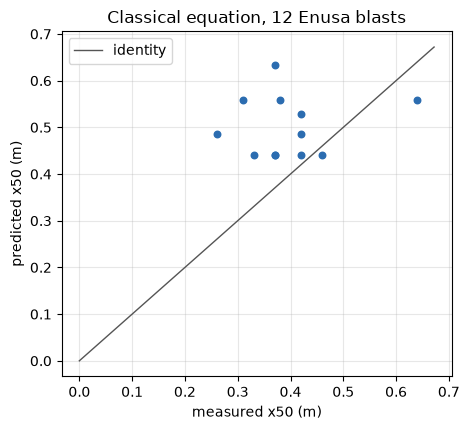

In [5]:
# Predict the 12 Enusa blasts and score them against the measurements
enusa = [b for b in train if b.site == "Enusa"]
predictions = arm.predict(enusa)
score = bf.score(enusa, predictions, method="kuznetsov")
print("blasts scored:", score.n_scored, "| abstained:", score.n_abstained)
print(f"RMSE = {score.rmse_m:.3f} m | bias = {score.bias_m:+.3f} m | MAE = {score.mae_m:.3f} m | MAPE = {score.mape_pct:.1f} %")
print(f"Pearson r2 (the correlation, squared) = {score.pearson_r2:.3f}")
print(f"variance explained about the identity line = {score.r2_identity:.3f}")
print("same as the committed score:", abs(score.r2_identity - artifact["scores"]["kuznetsov"]["r2_identity"]) < 1e-9)

measured = np.array([b.x50_m for b in enusa])
predicted = np.array([p.x50_m for p in predictions])
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(measured, predicted, s=22, color="#2b6cb0")
limit = max(measured.max(), predicted.max()) * 1.05
ax.plot([0, limit], [0, limit], color="#555", lw=1, label="identity")
ax.set_xlabel("measured x50 (m)")
ax.set_ylabel("predicted x50 (m)")
ax.set_title("Classical equation, 12 Enusa blasts")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Results

**The equation is a product of four visible factors.** Written term by term it reproduces the engine to machine precision, and the committed artifact holds the same prediction to six decimals. Nothing is hidden inside the arm: it reconstructs the pattern, looks up one factor and applies the formula.

**On Enusa the classical prediction is high.** The engine predicts coarser fragments than were measured on average (the bias is positive), and the predicted sizes vary in a narrower band than the measured ones. The parity plot shows the cloud above the identity line.

**Two statistics, two stories.** The Pearson r2 and the variance explained about the identity line are different quantities with different meanings, and the product always names which one it reports. Here they differ sharply because inside one campaign the measured sizes vary very little, so a prediction that is 0.1 m high on average explains less than a constant would. This is not a defect of the equation at Enusa; it is why a score inside one site says little, and why the product later pools many sites.

**What this does not show.** The rock factor of Enusa came from the published predictions for this very campaign, so the agreement of the level is partly circular. The next notebook opens that number and shows what is, and is not, borrowed.

## Summary

- The classical equation is four factors: a volume term, a hole-size term, a strength correction and one rock factor.
- The engine, a by-hand calculation and the committed artifact agree on the same blast.
- Inside one campaign a score is dominated by the small spread of the measurements; compare scores across sites, not within one.
- Next: notebook 02 opens the rock factor, the one number the equation cannot compute from the table.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (Eq. 1, the corpus)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (Eqs. 2 and 3, the equation and its units)
- Kuznetsov 1973 and Cunningham 1983, 1987 and 2005 are the originals of the equation and its corrections; the SDD records that their primary texts were not held, so this notebook cites them only through the two papers above.
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/